## Danish AIS 01 Shared Corridor Day (Flag 1)

### Dataset Overview
Constructed AIS-style observations in the open-water Fehmarn Belt. This sample contains 48 vessels and 1,136 observations within 00:00–16:00 on one constructed day. Raw downloaded Danish AIS files are unchanged.

![Corrected geographic overview](visualizations/overview_map.png)


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does vessel activity organize itself spatially and temporally across the corridor?

#### Analysis action

Compare the time chart with the mapped trajectories before describing the corridor pattern.

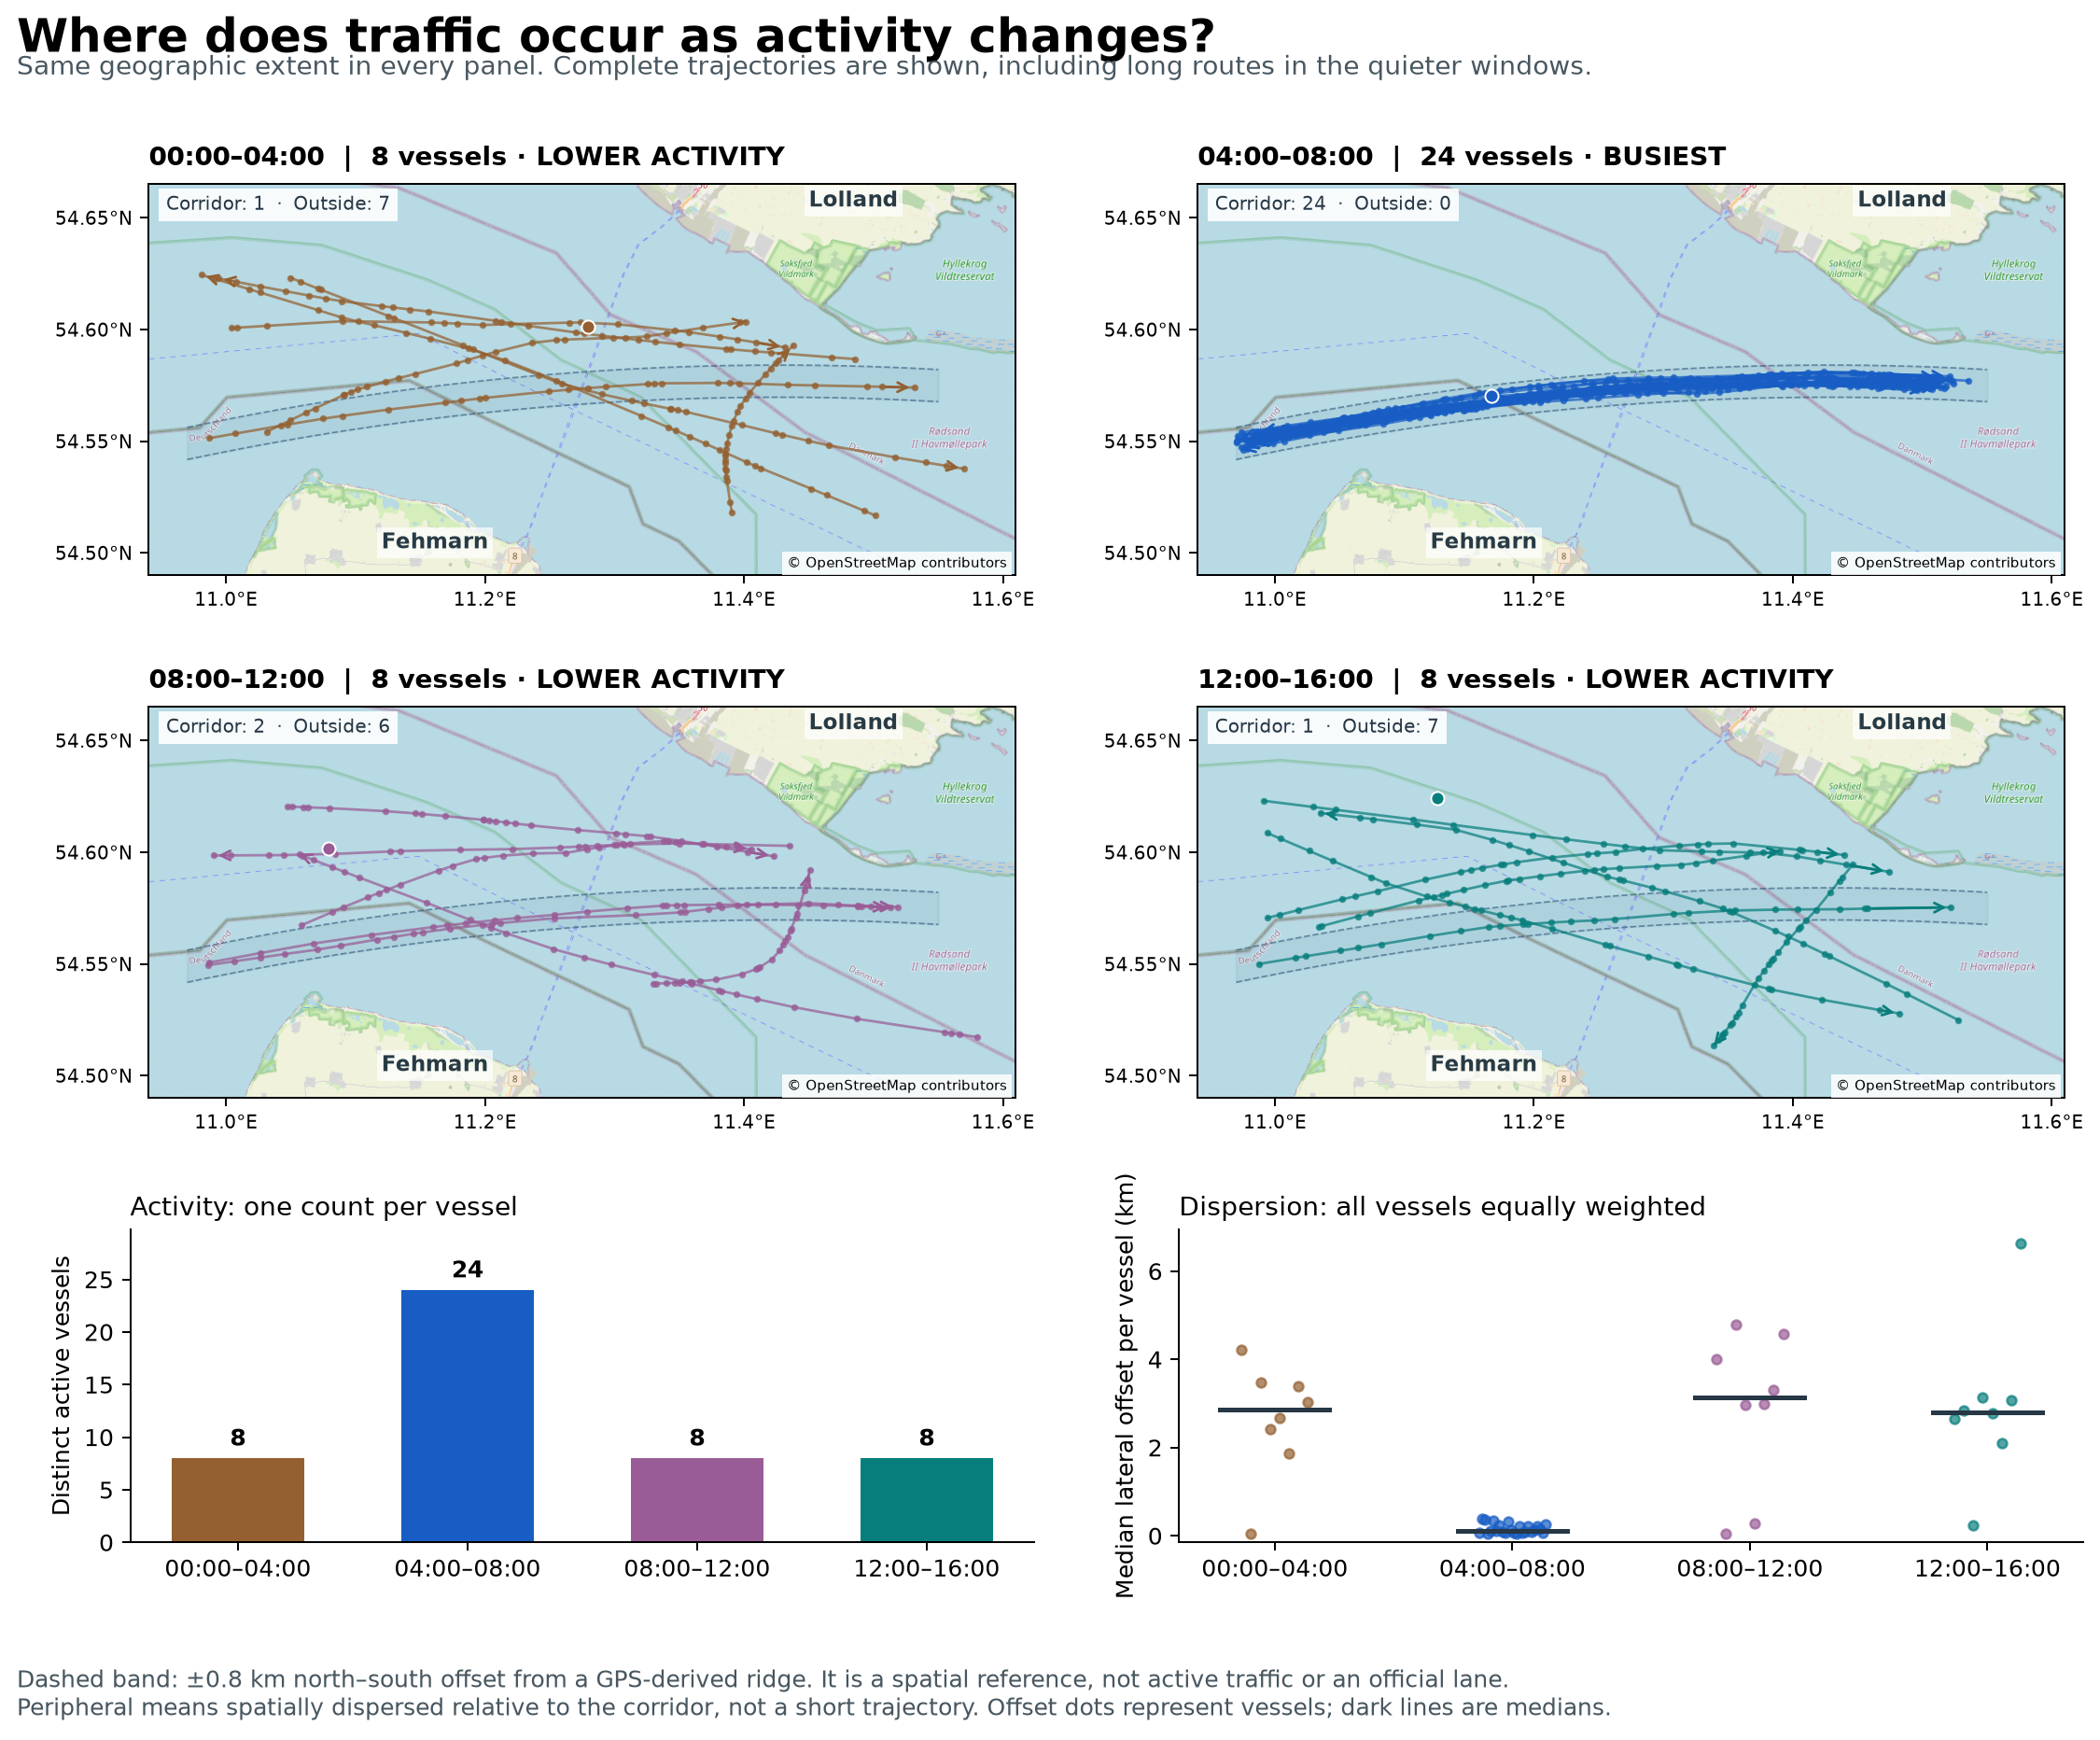

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
def fit_corridor(frame):
    """Find the dominant GPS ridge without timestamps, speed or draught.

    Polynomial candidates come from geometrically well-conditioned tracks;
    the final score uses all positions. Neither track length nor longitude
    span is a peripheral/corridor classification rule.
    """
    x=frame['lon'].to_numpy();y=frame['lat'].to_numpy();candidates=[]
    for _,group in frame.groupby('trajectory_id'):
        if group.lon.max()-group.lon.min()>.12 and len(group)>=4:
            curve=np.polyfit(group.lon,group.lat,2)
            residual=np.abs(y-np.polyval(curve,x))*111.32
            candidates.append((np.count_nonzero(residual<.6),curve))
    curve=max(candidates,key=lambda row:row[0])[1]
    for _ in range(3):
        inlier=np.abs(y-np.polyval(curve,x))*111.32<.6
        curve=np.polyfit(x[inlier],y[inlier],2)
    # A fixed 0.8-km proximity band is stated on the map. The centerline is
    # estimated from observed coordinates, not an external lane attribute.
    return curve,.8/111.32

d=df.copy()
curve,half=fit_corridor(d)
# Lateral offset is the absolute north-south latitude residual, converted
# with 111.32 km/degree. It is not shortest geodesic distance to the curve.
d['lateral_offset_km']=np.abs(d.lat-np.polyval(curve,d.lon))*111.32
d['within_corridor']=d.lateral_offset_km.le(.8)
spatial=d.groupby('trajectory_id').agg(within_corridor_share=('within_corridor','mean'),median_lateral_offset_km=('lateral_offset_km','median'))
spatial['zone']=np.where(spatial.within_corridor_share.ge(.6),'Corridor vicinity','Outside corridor')
d['zone']=d.trajectory_id.map(spatial.zone)

d['timestamp']=pd.to_datetime(d['timestamp'])
d['period']=(d['timestamp'].dt.hour//4)*4
profile=d.groupby('period')['trajectory_id'].nunique().reindex([0,4,8,12],fill_value=0).rename('active_vessels').to_frame()
zone_counts=d.groupby(['period','zone']).trajectory_id.nunique().unstack(fill_value=0)
profile['corridor_vessels']=zone_counts['Corridor vicinity']
profile['outside_corridor_vessels']=zone_counts['Outside corridor']
vessel_offsets=d.groupby(['period','trajectory_id']).lateral_offset_km.median()
profile['median_vessel_lateral_offset_km']=vessel_offsets.groupby('period').median()
print(profile.round(3))
# Geographic comparison: use identical axes for all four windows.
fig,axes=plt.subplots(2,2,figsize=(14,7),sharex=True,sharey=True)
colors={0:'#946031',4:'#175dc4',8:'#995c96',12:'#087e7c'}
for ax,period in zip(axes.flat,[0,4,8,12]):
    for tid,g in d[d.period.eq(period)].groupby('trajectory_id'):
        g=g.sort_values('timestamp'); ax.plot(g.lon,g.lat,color=colors[period],alpha=.72)
    x=np.linspace(10.97,11.55,200)
    for delta in [-half,half]:ax.plot(x,np.polyval(curve,x)+delta,'--',color='#254b70',lw=.7)
    n=int(profile.loc[period,'active_vessels'])
    ax.set(xlim=(10.94,11.61),ylim=(54.49,54.665),title=f'{period:02d}:00–{period+4:02d}:00 | {n} vessels',xlabel='Longitude',ylabel='Latitude')
    ax.set_aspect(1/0.58)
plt.show()

from IPython.display import Image, display
display(Image(filename="notebook_plots/q1_1.png"))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "temporal_spatial",
  "insight": "Traffic is concentrated along a narrow through-corridor during the busier parts of the day, while lower-activity periods show more peripheral movement.",
  "insight_value": {
    "pattern": "central corridor concentration",
    "comparison": "busy versus lower-activity periods"
  },
  "plot": {
    "plot_type": "time_faceted_maps_and_activity_and_dispersion_charts",
    "title": "Spatial concentration versus dispersion across four-hour activity windows",
    "file": "visualizations/corridor_activity_by_time.png",
    "description": "Four maps share the same geographic extent and coastline. The busiest window (04:00–08:00, 24 vessels) shows a concentrated narrow corridor. The quieter windows contain mostly dispersed complete routes with differing directions, together with a minority of full corridor transits (00:00–04:00: 1 of 8 vessels; 08:00–12:00: 2 of 8 vessels; 12:00–16:00: 1 of 8 vessels). Each map labels its corridor and outside counts. Colors identify time windows, not route length. The lower charts show distinct active-vessel counts and each vessel's median absolute north-south offset from the GPS-derived corridor; dark lines mark window medians. Counts and offsets come from the same complete tracks. No claim is made about unsampled hours after 16:00."
  },
  "question": "How does vessel activity organize itself spatially and temporally across the corridor?",
  "actionable_insight": "Compare the time chart with the mapped trajectories before describing the corridor pattern.",
  "code": "import numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\ndef fit_corridor(frame):\n    \"\"\"Find the dominant GPS ridge without timestamps, speed or draught.\n\n    Polynomial candidates come from geometrically well-conditioned tracks;\n    the final score uses all positions. Neither track length nor longitude\n    span is a peripheral/corridor classification rule.\n    \"\"\"\n    x=frame['lon'].to_numpy();y=frame['lat'].to_numpy();candidates=[]\n    for _,group in frame.groupby('trajectory_id'):\n        if group.lon.max()-group.lon.min()>.12 and len(group)>=4:\n            curve=np.polyfit(group.lon,group.lat,2)\n            residual=np.abs(y-np.polyval(curve,x))*111.32\n            candidates.append((np.count_nonzero(residual<.6),curve))\n    curve=max(candidates,key=lambda row:row[0])[1]\n    for _ in range(3):\n        inlier=np.abs(y-np.polyval(curve,x))*111.32<.6\n        curve=np.polyfit(x[inlier],y[inlier],2)\n    # A fixed 0.8-km proximity band is stated on the map. The centerline is\n    # estimated from observed coordinates, not an external lane attribute.\n    return curve,.8/111.32\n\nd=df.copy()\ncurve,half=fit_corridor(d)\n# Lateral offset is the absolute north-south latitude residual, converted\n# with 111.32 km/degree. It is not shortest geodesic distance to the curve.\nd['lateral_offset_km']=np.abs(d.lat-np.polyval(curve,d.lon))*111.32\nd['within_corridor']=d.lateral_offset_km.le(.8)\nspatial=d.groupby('trajectory_id').agg(within_corridor_share=('within_corridor','mean'),median_lateral_offset_km=('lateral_offset_km','median'))\nspatial['zone']=np.where(spatial.within_corridor_share.ge(.6),'Corridor vicinity','Outside corridor')\nd['zone']=d.trajectory_id.map(spatial.zone)\n\nd['timestamp']=pd.to_datetime(d['timestamp'])\nd['period']=(d['timestamp'].dt.hour//4)*4\nprofile=d.groupby('period')['trajectory_id'].nunique().reindex([0,4,8,12],fill_value=0).rename('active_vessels').to_frame()\nzone_counts=d.groupby(['period','zone']).trajectory_id.nunique().unstack(fill_value=0)\nprofile['corridor_vessels']=zone_counts['Corridor vicinity']\nprofile['outside_corridor_vessels']=zone_counts['Outside corridor']\nvessel_offsets=d.groupby(['period','trajectory_id']).lateral_offset_km.median()\nprofile['median_vessel_lateral_offset_km']=vessel_offsets.groupby('period').median()\nprint(profile.round(3))\n# Geographic comparison: use identical axes for all four windows.\nfig,axes=plt.subplots(2,2,figsize=(14,7),sharex=True,sharey=True)\ncolors={0:'#946031',4:'#175dc4',8:'#995c96',12:'#087e7c'}\nfor ax,period in zip(axes.flat,[0,4,8,12]):\n    for tid,g in d[d.period.eq(period)].groupby('trajectory_id'):\n        g=g.sort_values('timestamp'); ax.plot(g.lon,g.lat,color=colors[period],alpha=.72)\n    x=np.linspace(10.97,11.55,200)\n    for delta in [-half,half]:ax.plot(x,np.polyval(curve,x)+delta,'--',color='#254b70',lw=.7)\n    n=int(profile.loc[period,'active_vessels'])\n    ax.set(xlim=(10.94,11.61),ylim=(54.49,54.665),title=f'{period:02d}:00–{period+4:02d}:00 | {n} vessels',xlabel='Longitude',ylabel='Latitude')\n    ax.set_aspect(1/0.58)\nplt.show()\n",
  "insight_type": "temporal_dynamics",
  "evidence": {
    "spatial_group_rule": "A vessel belongs to Corridor vicinity when at least 60% of its GPS positions have an absolute north-south offset of at most 0.8 km from the fitted ridge; otherwise Outside corridor. Track length is not a grouping rule; outside routes may cross the band.",
    "corridor_definition": "GPS-derived dominant quadratic ridge, scored against all observed positions and refined on its inliers. The dashed band is a fixed ±0.8 km north-south latitude offset. No external lane attribute, time, speed or draught enters its fit.",
    "dispersion_metric": "For each vessel, median(abs(latitude - fitted_latitude(longitude)) * 111.32) km; then the median across vessels in a window. This is north-south lateral offset, not shortest geodesic distance. Each vessel has equal weight.",
    "observation_window": "00:00–16:00; counts measure activity within the selected sample, not population-level Danish AIS traffic.",
    "computed_statistics": {
      "window_hours": 4,
      "counting_unit": "Distinct active vessel per window; trajectory_id is only a grouping key and maps one-to-one to vessel_id in this sample.",
      "active_vessels": {
        "0": 8,
        "4": 24,
        "8": 8,
        "12": 8
      },
      "corridor_vessels": {
        "0": 1,
        "4": 24,
        "8": 2,
        "12": 1
      },
      "outside_corridor_vessels": {
        "0": 7,
        "4": 0,
        "8": 6,
        "12": 7
      },
      "median_vessel_lateral_offset_km": {
        "0": 2.851,
        "4": 0.117,
        "8": 3.139,
        "12": 2.807
      },
      "share_positions_outside_08km_band": {
        "0": 0.7979,
        "4": 0.0,
        "8": 0.6915,
        "12": 0.8085
      },
      "reference_band_full_north_south_width_km": 1.6
    }
  },
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "vessel_id"
  ]
}

### **Question 2**: What movement regimes coexist within the same corridor?

#### Analysis action

Compare the full trajectory-level speed distributions rather than only their averages.

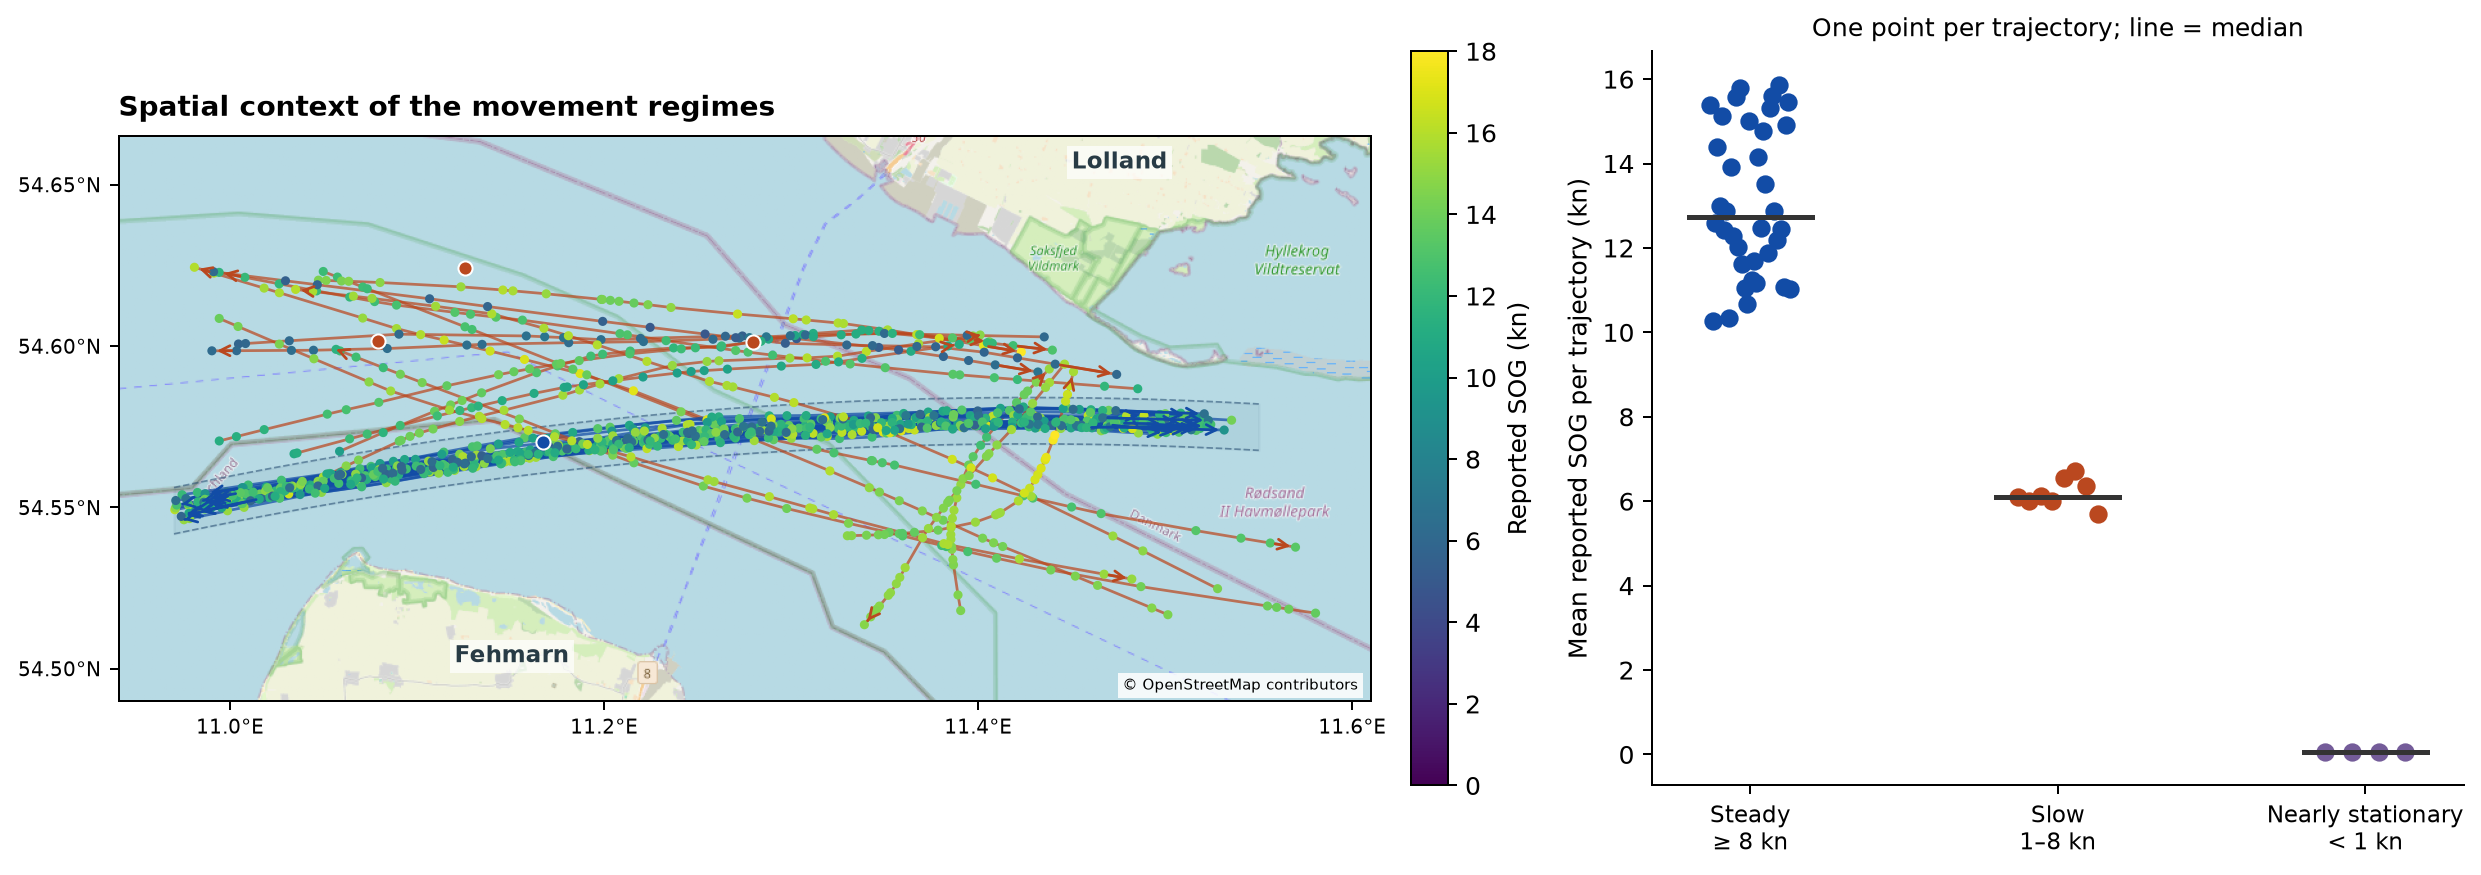

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.groupby('trajectory_id')['sog'].mean().rename('mean_sog').reset_index(); d['regime']=pd.cut(d.mean_sog,[-1,1,8,100],right=False,labels=['nearly stationary','slow','steady']); print(d.groupby('regime',observed=True).mean_sog.agg(['count','median','min','max']))
from IPython.display import Image, display
display(Image(filename="notebook_plots/q2_1.png"))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "movement_regime",
  "insight": "The corridor contains a mixture of steadily moving vessels and slower or nearly stationary tracks, creating different movement regimes within the same maritime area.",
  "insight_value": {
    "regimes": [
      "steady movement",
      "slower or nearly stationary movement"
    ]
  },
  "plot": {
    "plot_type": "map_and_trajectory_strip_plot",
    "title": "Trajectory-level speed regime distributions",
    "file": "visualizations/movement_regimes.png",
    "description": "Left: all tracks with reported SOG colors and geographic context. Right: one mean reported SOG value per trajectory, with medians; speeds are not taken from the first observation."
  },
  "question": "What movement regimes coexist within the same corridor?",
  "actionable_insight": "Compare the full trajectory-level speed distributions rather than only their averages.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.groupby('trajectory_id')['sog'].mean().rename('mean_sog').reset_index(); d['regime']=pd.cut(d.mean_sog,[-1,1,8,100],right=False,labels=['nearly stationary','slow','steady']); print(d.groupby('regime',observed=True).mean_sog.agg(['count','median','min','max']))",
  "insight_type": "overall_pattern",
  "evidence": {
    "computed_statistics": {
      "steady_trajectories": 36,
      "slow_trajectories": 8,
      "nearly_stationary_trajectories": 4
    }
  },
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "point_speed",
    "vessel_id"
  ]
}

### **Question 3**: How does reported vessel draught differ between the narrow through-corridor and its edges?

#### Analysis action

Compare the full draught distributions and their overlap, not just the mean draught of each zone.

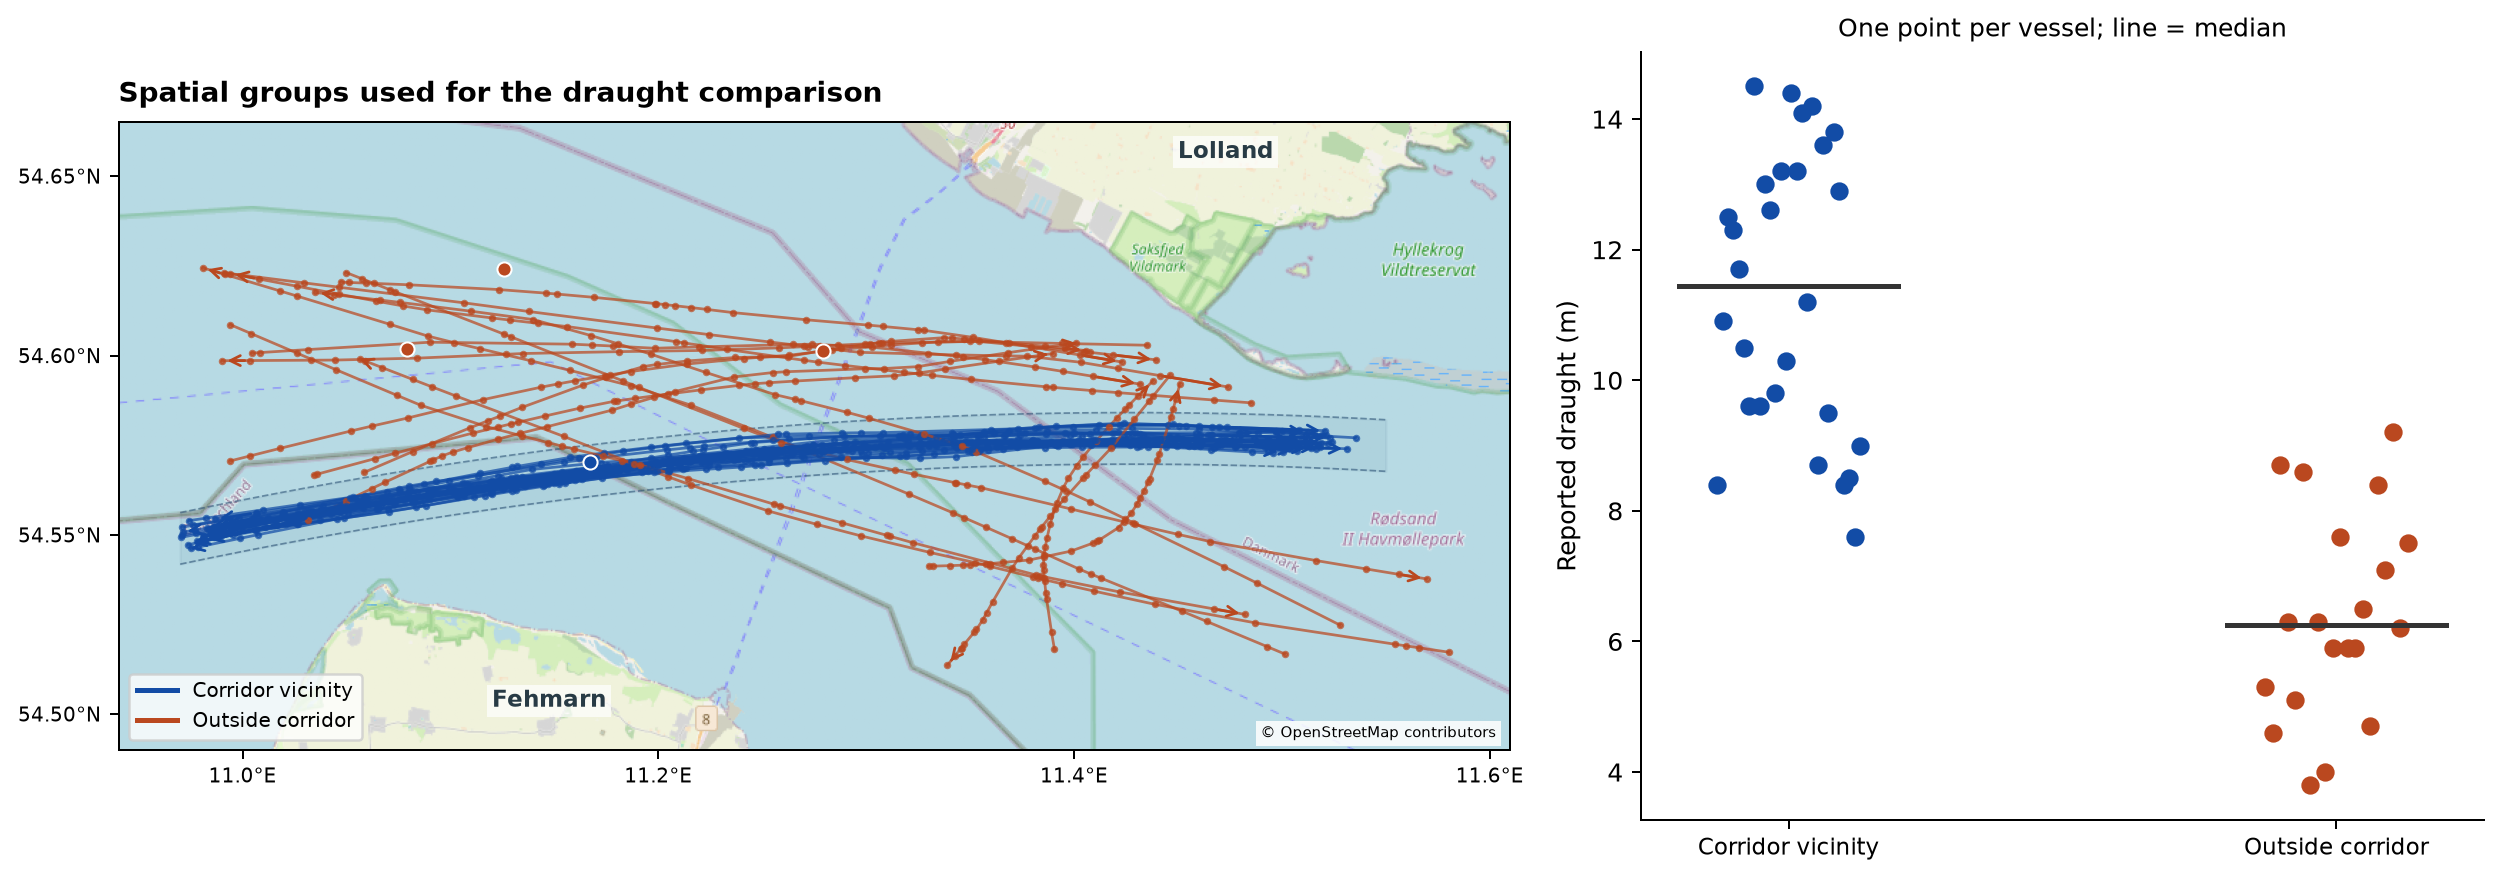

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
def fit_corridor(frame):
    """Find the dominant GPS ridge without timestamps, speed or draught.

    Polynomial candidates come from geometrically well-conditioned tracks;
    the final score uses all positions. Neither track length nor longitude
    span is a peripheral/corridor classification rule.
    """
    x=frame['lon'].to_numpy();y=frame['lat'].to_numpy();candidates=[]
    for _,group in frame.groupby('trajectory_id'):
        if group.lon.max()-group.lon.min()>.12 and len(group)>=4:
            curve=np.polyfit(group.lon,group.lat,2)
            residual=np.abs(y-np.polyval(curve,x))*111.32
            candidates.append((np.count_nonzero(residual<.6),curve))
    curve=max(candidates,key=lambda row:row[0])[1]
    for _ in range(3):
        inlier=np.abs(y-np.polyval(curve,x))*111.32<.6
        curve=np.polyfit(x[inlier],y[inlier],2)
    # A fixed 0.8-km proximity band is stated on the map. The centerline is
    # estimated from observed coordinates, not an external lane attribute.
    return curve,.8/111.32

d=df.copy()
curve,half=fit_corridor(d)
# Lateral offset is the absolute north-south latitude residual, converted
# with 111.32 km/degree. It is not shortest geodesic distance to the curve.
d['lateral_offset_km']=np.abs(d.lat-np.polyval(curve,d.lon))*111.32
d['within_corridor']=d.lateral_offset_km.le(.8)
spatial=d.groupby('trajectory_id').agg(within_corridor_share=('within_corridor','mean'),median_lateral_offset_km=('lateral_offset_km','median'))
spatial['zone']=np.where(spatial.within_corridor_share.ge(.6),'Corridor vicinity','Outside corridor')
d['zone']=d.trajectory_id.map(spatial.zone)

vessels=d.groupby('trajectory_id').agg(zone=('zone','first'),draught=('draught','first')); print(vessels.groupby('zone').draught.agg(['count','median','min','max'])); vessels.boxplot(column='draught',by='zone'); plt.show()
from IPython.display import Image, display
display(Image(filename="notebook_plots/q3_1.png"))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_attribute",
  "insight": "Vessels in the narrow through-corridor have noticeably deeper reported draughts than vessels using the corridor edges.",
  "insight_value": {
    "comparison": "narrow through-corridor versus corridor edges",
    "attribute": "reported draught"
  },
  "plot": {
    "plot_type": "map_and_vessel_strip_plot",
    "title": "Draught distributions by corridor position",
    "file": "visualizations/draught_by_corridor_position.png",
    "description": "The map shows spatial groups defined by GPS proximity to the dominant ridge, independently of time and track length. Each dot in the right panel is one vessel draught; the horizontal line is the group median. The blue group has at least 60% of positions within the ±0.8 km band; the orange group contains all remaining tracks."
  },
  "question": "How does reported vessel draught differ between the narrow through-corridor and its edges?",
  "actionable_insight": "Compare the full draught distributions and their overlap, not just the mean draught of each zone.",
  "code": "import numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\ndef fit_corridor(frame):\n    \"\"\"Find the dominant GPS ridge without timestamps, speed or draught.\n\n    Polynomial candidates come from geometrically well-conditioned tracks;\n    the final score uses all positions. Neither track length nor longitude\n    span is a peripheral/corridor classification rule.\n    \"\"\"\n    x=frame['lon'].to_numpy();y=frame['lat'].to_numpy();candidates=[]\n    for _,group in frame.groupby('trajectory_id'):\n        if group.lon.max()-group.lon.min()>.12 and len(group)>=4:\n            curve=np.polyfit(group.lon,group.lat,2)\n            residual=np.abs(y-np.polyval(curve,x))*111.32\n            candidates.append((np.count_nonzero(residual<.6),curve))\n    curve=max(candidates,key=lambda row:row[0])[1]\n    for _ in range(3):\n        inlier=np.abs(y-np.polyval(curve,x))*111.32<.6\n        curve=np.polyfit(x[inlier],y[inlier],2)\n    # A fixed 0.8-km proximity band is stated on the map. The centerline is\n    # estimated from observed coordinates, not an external lane attribute.\n    return curve,.8/111.32\n\nd=df.copy()\ncurve,half=fit_corridor(d)\n# Lateral offset is the absolute north-south latitude residual, converted\n# with 111.32 km/degree. It is not shortest geodesic distance to the curve.\nd['lateral_offset_km']=np.abs(d.lat-np.polyval(curve,d.lon))*111.32\nd['within_corridor']=d.lateral_offset_km.le(.8)\nspatial=d.groupby('trajectory_id').agg(within_corridor_share=('within_corridor','mean'),median_lateral_offset_km=('lateral_offset_km','median'))\nspatial['zone']=np.where(spatial.within_corridor_share.ge(.6),'Corridor vicinity','Outside corridor')\nd['zone']=d.trajectory_id.map(spatial.zone)\n\nvessels=d.groupby('trajectory_id').agg(zone=('zone','first'),draught=('draught','first')); print(vessels.groupby('zone').draught.agg(['count','median','min','max'])); vessels.boxplot(column='draught',by='zone'); plt.show()",
  "insight_type": "group_comparison",
  "evidence": {
    "spatial_group_rule": "A vessel belongs to Corridor vicinity when at least 60% of its GPS positions have an absolute north-south offset of at most 0.8 km from the fitted ridge; otherwise Outside corridor. Track length is not a grouping rule; outside routes may cross the band.",
    "corridor_definition": "GPS-derived dominant quadratic ridge, scored against all observed positions and refined on its inliers. The dashed band is a fixed ±0.8 km north-south latitude offset. No external lane attribute, time, speed or draught enters its fit.",
    "computed_statistics": {
      "Corridor vicinity": {
        "vessels": 28,
        "median_draught_m": 11.45,
        "min_draught_m": 7.6,
        "max_draught_m": 14.5
      },
      "Outside corridor": {
        "vessels": 20,
        "median_draught_m": 6.25,
        "min_draught_m": 3.8,
        "max_draught_m": 9.2
      }
    }
  },
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "draught",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 1)

The case shows a time-varying maritime corridor with a concentrated through-route, slower peripheral activity, and a spatial difference in reported vessel draught.